In [1]:
import pathlib

print("Current working directory:", pathlib.Path().resolve())

Current working directory: /Users/lms/Documents/Forschung/textClust_hpo


In [2]:
import pandas as pd
import os
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from moocore import hypervolume

from smac_hpo.evaluation.utils import build_results_csv, store_results_csv, load_results_csv, normalize, pareto_optimal_points 
from smac_hpo.evaluation.utils import COLORS, COLOR_PALETTE, ALGORITHM_ORDER, NUM_SEEDS, NUM_REPS
from smac_hpo.evaluation.utils import PANEL_HEIGHT, facet_aspect, set_publication_style
set_publication_style()

FIGURES_DIR = pathlib.Path("figures")
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

In [3]:
full_results_df = load_results_csv()
cv_results = full_results_df[full_results_df["config_source"] == "cv"].copy()
assert not cv_results.empty, "No cross-validation results found in the loaded results CSV."
for _, group in cv_results.groupby(["dataset"]):
    cv_results.loc[group.index, ["avg_throughput_normalized", "adj_mutual_info_final_normalized"]] = normalize(group, columns=["avg_throughput", "adj_mutual_info_final"], use_log=[True, False])[["avg_throughput", "adj_mutual_info_final"]].values

cv_results.head()

,config_source,config_id,algorithm,config,config_index,dataset,is_test,rand,adj_rand,mutual_info,...,time_gap,sigma,threshold_momentum,min_weight,term_fading,batch_size,threshold,window,avg_throughput_normalized,adj_mutual_info_final_normalized
0,cv,FSD-SBERT_best_config_loo_['Arabic_Twitter Sem...,FSD-SBERT,best_config_loo_['Arabic_Twitter Semantic40-T'...,0,Arabic_7,False,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,8.0,0.5,125.0,0.145316,0.586442
1,cv,FSD-SBERT_best_config_loo_['Arabic_Twitter Sem...,FSD-SBERT,best_config_loo_['Arabic_Twitter Semantic40-T'...,0,Arabic_Twitter,True,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,8.0,0.5,125.0,0.699281,0.662472
2,cv,FSD-SBERT_best_config_loo_['Arabic_Twitter Sem...,FSD-SBERT,best_config_loo_['Arabic_Twitter Semantic40-T'...,0,CrisisLexT6,False,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,8.0,0.5,125.0,0.670925,0.472189
3,cv,FSD-SBERT_best_config_loo_['Arabic_Twitter Sem...,FSD-SBERT,best_config_loo_['Arabic_Twitter Semantic40-T'...,0,CrisisLexT7,False,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,8.0,0.5,125.0,0.654805,0.469377
4,cv,FSD-SBERT_best_config_loo_['Arabic_Twitter Sem...,FSD-SBERT,best_config_loo_['Arabic_Twitter Semantic40-T'...,0,CrisisLexT26,False,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,8.0,0.5,125.0,0.709597,0.836325


In [4]:
from tqdm import tqdm
results = []

for (alg, ds), group in tqdm(cv_results.groupby(["algorithm","dataset"]), desc="Processing dataset algorithm groups"):
    for num_seeds in NUM_SEEDS:
        for i in range(NUM_REPS):
            seeds = np.random.choice(group["seed"].unique(), size=num_seeds, replace=False)
            subgroup = group[group["seed"].isin(seeds)].copy()
            test_group = subgroup[subgroup["is_test"] == True]
            assert not test_group.empty, f"No test results found for dataset '{ds}' in the cross-validation results."
            
            train_group = subgroup[subgroup["is_test"] == False]
            assert not train_group.empty, f"No training results found for dataset '{ds}' in the cross-validation results."
            
            test_hv = hypervolume(test_group[["avg_throughput_normalized", "adj_mutual_info_final_normalized"]].values, ref=[0.0, 0.0], maximise=True)
            assert test_hv > 0, f"Hypervolume for test results of dataset '{ds}' is not positive."
            
            for (loo_ds_1, loo_ds_2), fold in train_group.groupby(["loo_dataset_1", "loo_dataset_2"]):
                assert ds not in [loo_ds_1, loo_ds_2], f"Dataset '{ds}' should not be in the held-out datasets for its own cross-validation results."
                fold_hv = hypervolume(fold[["avg_throughput_normalized", "adj_mutual_info_final_normalized"]].values, ref=[0.0, 0.0], maximise=True)
                assert fold_hv > 0, f"Hypervolume for training results of dataset '{ds}' with held-out datasets '{loo_ds_1}' and '{loo_ds_2}' is not positive."
                
                results.append({
                    "dataset": ds,
                    "algorithm": alg,
                    "loo_dataset_1": loo_ds_1,
                    "loo_dataset_2": loo_ds_2,
                    "test_hv": test_hv,
                    "train_hv": fold_hv,
                    "hv_ratio": test_hv / fold_hv,
                    "seeds": str(seeds.tolist()),
                    "n_seeds" : num_seeds,
                    "n_reps" : i
                })

generalisation_results_df = pd.DataFrame(results)

generalisation_results_df

Processing dataset algorithm groups: 100%|██████████| 48/48 [00:38<00:00,  1.26it/s]


,dataset,algorithm,loo_dataset_1,loo_dataset_2,test_hv,train_hv,hv_ratio,seeds,n_seeds,n_reps
0,Arabic_7,FSD-SBERT,Arabic_Twitter,Semantic40-T,0.456496,0.424510,1.075346,[5.0],1,0
1,Arabic_7,FSD-SBERT,CrisisNLP,CrisisMMD,0.456496,0.612523,0.745271,[5.0],1,0
2,Arabic_7,FSD-SBERT,Event2012,CrisisLexT26,0.456496,0.433066,1.054101,[5.0],1,0
3,Arabic_7,FSD-SBERT,MAVEN,HumAID,0.456496,0.466395,0.978775,[5.0],1,0
4,Arabic_7,FSD-SBERT,Mix_Data,CrisisLexT6,0.456496,0.484474,0.942251,[5.0],1,0
...,...,...,...,...,...,...,...,...,...,...
151195,Semantic5-T,textClust,Event2012,CrisisLexT26,0.749209,0.766403,0.977565,"[7.0, 4.0, 3.0, 10.0, 1.0, 6.0, 8.0, 2.0, 5.0,...",10,44
151196,Semantic5-T,textClust,KBP,Arabic_7,0.749209,0.733541,1.021359,"[7.0, 4.0, 3.0, 10.0, 1.0, 6.0, 8.0, 2.0, 5.0,...",10,44
151197,Semantic5-T,textClust,MAVEN,HumAID,0.749209,0.733439,1.021501,"[7.0, 4.0, 3.0, 10.0, 1.0, 6.0, 8.0, 2.0, 5.0,...",10,44
151198,Semantic5-T,textClust,Mix_Data,CrisisLexT6,0.749209,0.753250,0.994635,"[7.0, 4.0, 3.0, 10.0, 1.0, 6.0, 8.0, 2.0, 5.0,...",10,44


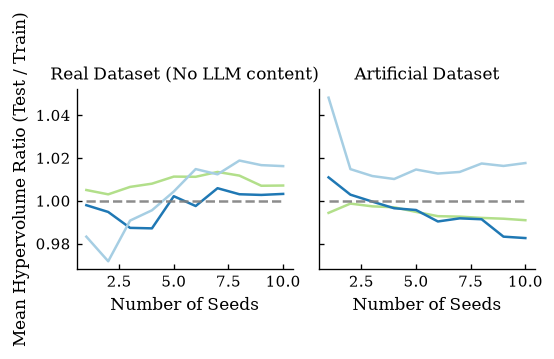

In [5]:
from matplotlib.lines import Line2D

df = generalisation_results_df.copy()
df["is_artificial"] = np.where(df["dataset"].str.contains("Semantic"), "Artificial Dataset", "Real Dataset (No LLM content)")

df = (
    df.groupby(["dataset", "algorithm", "n_seeds", "is_artificial"])["hv_ratio"]
    .median()
    .reset_index()
)

g = sns.FacetGrid(df, col="is_artificial", hue="algorithm", hue_order=ALGORITHM_ORDER, palette=COLORS, sharey=True, height=PANEL_HEIGHT, aspect=facet_aspect(2))
g.map_dataframe(sns.lineplot, x="n_seeds", y="hv_ratio", estimator="mean", errorbar=None)

legend_handles = [
    Line2D([0], [0], color=COLORS[alg], label=alg, linewidth=2) for alg in ALGORITHM_ORDER
]
g.set_titles("{col_name}")
legend_fig = plt.figure()
legend_fig.legend(handles=legend_handles, loc="center", ncol=3)
legend_fig.savefig(
    FIGURES_DIR / "generalization_legend.pdf",
    format="pdf",
    bbox_inches="tight",
    pad_inches=0,
)
plt.close(legend_fig)
g.set_axis_labels("Number of Seeds", "Mean Hypervolume Ratio (Test / Train)")

for ax in g.axes.flatten():
    ax.hlines(y=1.0, xmin=1, xmax=10, color="grey", linestyle="--", alpha=0.9,)

g.figure.savefig(
    FIGURES_DIR / "generalization_hypervolume_ratio.pdf",
    format="pdf",
    bbox_inches="tight",
    pad_inches=0.1,
)

#sns.lineplot(data=df, x="n_seeds", y="hv_ratio", hue="algorithm", palette=COLOR_PALETTE, estimator="median", hue_order=ALGORITHM_ORDER)
#plt.ylim(.5, 1.5)
#plt.title("Generalization Performance Across Datasets and Algorithms")
#plt.xlabel("Number of Seeds")
#plt.ylabel("Hypervolume Ratio (Test / Train)")